In [2]:
# Basic Import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
# Modelling
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Ridge,Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
import warnings
warnings.filterwarnings('ignore')

In [1]:
import sys
print(sys.executable)

import sklearn
print(sklearn.__file__)

d:\VS CODE\mlproject_kr\venv\python.exe
d:\VS CODE\mlproject_kr\venv\lib\site-packages\sklearn\__init__.py


In [4]:
df = pd.read_csv('data/stud.csv')

In [5]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [8]:
X = df.drop(columns=['math_score'], axis=1)
y = df['math_score']

In [9]:
X.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,74
1,female,group C,some college,standard,completed,90,88
2,female,group B,master's degree,standard,none,95,93
3,male,group A,associate's degree,free/reduced,none,57,44
4,male,group C,some college,standard,none,78,75


In [10]:
print("Categories in 'gender' variable:     ",end=" " )
print(df['gender'].unique())

print("Categories in 'race_ethnicity' variable:  ",end=" ")
print(df['race_ethnicity'].unique())

print("Categories in'parental level of education' variable:",end=" " )
print(df['parental_level_of_education'].unique())

print("Categories in 'lunch' variable:     ",end=" " )
print(df['lunch'].unique())

print("Categories in 'test preparation course' variable:     ",end=" " )
print(df['test_preparation_course'].unique())

Categories in 'gender' variable:      ['female' 'male']
Categories in 'race_ethnicity' variable:   ['group B' 'group C' 'group A' 'group D' 'group E']
Categories in'parental level of education' variable: ["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']
Categories in 'lunch' variable:      ['standard' 'free/reduced']
Categories in 'test preparation course' variable:      ['none' 'completed']


In [11]:
y.head()

0    72
1    69
2    90
3    47
4    76
Name: math_score, dtype: int64

In [12]:
#create column transformer with 3 types of transformers: one for categorical features, one for numerical features and one for the rest of the features
num_features = X.select_dtypes(exclude="object").columns
cat_features = X.select_dtypes(include="object").columns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_transformer = StandardScaler()
oh_transformer = OneHotEncoder()

preprocessor = ColumnTransformer(
    [
        ("OneHotEncoder", oh_transformer, cat_features),
        ("StandardScaler", num_transformer, num_features),
    ]
)

In [13]:
X = preprocessor.fit_transform(X)
X.shape

(1000, 19)

In [14]:
#seperate the data into train and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((800, 19), (200, 19), (800,), (200,))

#### Create an Evaluate Function to give all metrics after model Training

In [15]:
def evaluate_model(true,predicted):
    mae = mean_absolute_error(true,predicted)
    mse = mean_squared_error(true,predicted)
    rmse = np.sqrt(mean_squared_error(true,predicted))
    r2_square = r2_score(true,predicted)
    return mae,mse,rmse,r2_square

In [16]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "K-Neighbors Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor(),
    "XGBRegressor": XGBRegressor(), 
    "CatBoosting Regressor": CatBoostRegressor(verbose=False),
    "AdaBoost Regressor": AdaBoostRegressor()
}
model_list = []
r2_list = []

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train)
    
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    train_mae, train_mse, train_rmse, train_r2 = evaluate_model(y_train, y_train_pred)
    test_mae, test_mse, test_rmse, test_r2 = evaluate_model(y_test, y_test_pred)
    
    print(f"Model: {list(models.keys())[i]}")
    print(f"Train R2 Score: {train_r2:.4f}")
    print(f"Test R2 Score: {test_r2:.4f}")
    print("-"*30)
    
    model_list.append(list(models.keys())[i])
    r2_list.append(test_r2)

    print('=' * 30)
    print('\n')

Model: Linear Regression
Train R2 Score: 0.8743
Test R2 Score: 0.8804
------------------------------


Model: Lasso
Train R2 Score: 0.8071
Test R2 Score: 0.8253
------------------------------


Model: Ridge
Train R2 Score: 0.8743
Test R2 Score: 0.8806
------------------------------


Model: K-Neighbors Regressor
Train R2 Score: 0.8555
Test R2 Score: 0.7838
------------------------------


Model: Decision Tree
Train R2 Score: 0.9997
Test R2 Score: 0.7586
------------------------------


Model: Random Forest Regressor
Train R2 Score: 0.9770
Test R2 Score: 0.8498
------------------------------


Model: XGBRegressor
Train R2 Score: 0.9955
Test R2 Score: 0.8278
------------------------------


Model: CatBoosting Regressor
Train R2 Score: 0.9589
Test R2 Score: 0.8516
------------------------------


Model: AdaBoost Regressor
Train R2 Score: 0.8489
Test R2 Score: 0.8488
------------------------------




In [17]:
pd.DataFrame(list(zip(model_list, r2_list)), columns=['Model Name', 'R2 Score']).sort_values(by='R2 Score', ascending=False)

,Model Name,R2 Score
2,Ridge,0.880593
0,Linear Regression,0.880433
7,CatBoosting Regressor,0.851632
5,Random Forest Regressor,0.849814
8,AdaBoost Regressor,0.848825
6,XGBRegressor,0.827797
1,Lasso,0.825320
3,K-Neighbors Regressor,0.783813
4,Decision Tree,0.758587


### Linear Regression

In [24]:
lin_model = LinearRegression(fit_intercept=True)
lin_model = lin_model.fit(X_train, y_train)
y_pred = lin_model.predict(X_test)
score = r2_score(y_test, y_pred)*100
print("Accuracy score is %.2f%%" % score)

Accuracy score is 88.04%


Text(0, 0.5, 'Predicted Values')

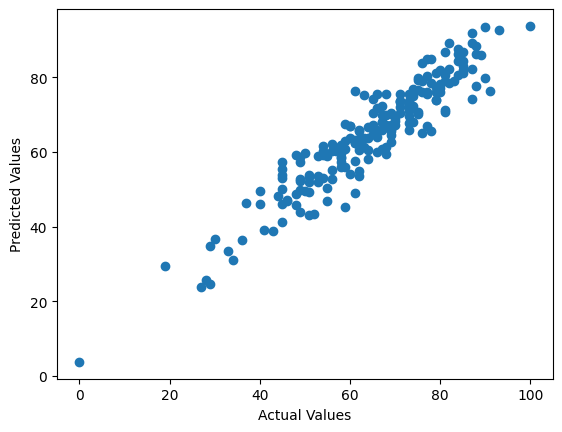

In [25]:
plt.scatter(y_test, y_pred);
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')

<Axes: xlabel='math_score'>

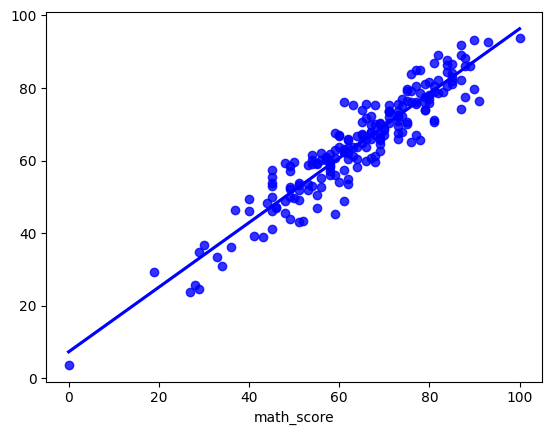

In [26]:
sns.regplot(x=y_test, y=y_pred, ci=None, color="b")

### Difference between actual and predicated values

In [29]:
pred_df = pd.DataFrame({'Actual Values': y_test, 'Predicted Values': y_pred, 'Difference': y_test - y_pred})

In [30]:
pred_df

,Actual Values,Predicted Values,Difference
521,91,76.387970,14.612030
737,53,58.885970,-5.885970
740,80,76.990265,3.009735
660,74,76.851804,-2.851804
411,84,87.627378,-3.627378
...,...,...,...
408,52,43.409149,8.590851
332,62,62.152214,-0.152214
208,74,67.888395,6.111605
613,65,67.022287,-2.022287
